## Predicting Medical Expenses for an Insurance Company Using Multiple Linear Regression

### **Introduction:** 
In this activity, we will explore the concept of linear regression using the `insurance.csv` dataset. Linear regression is a supervised learning technique used to predict the value of a dependent variable (in this case, `charges`, based on one or more independent variables (for example, `age`, `bmi`, `children`, etc.).

You can download the dataset from [here](https://www.kaggle.com/datasets/mirichoi0218/insurance?resource=download).

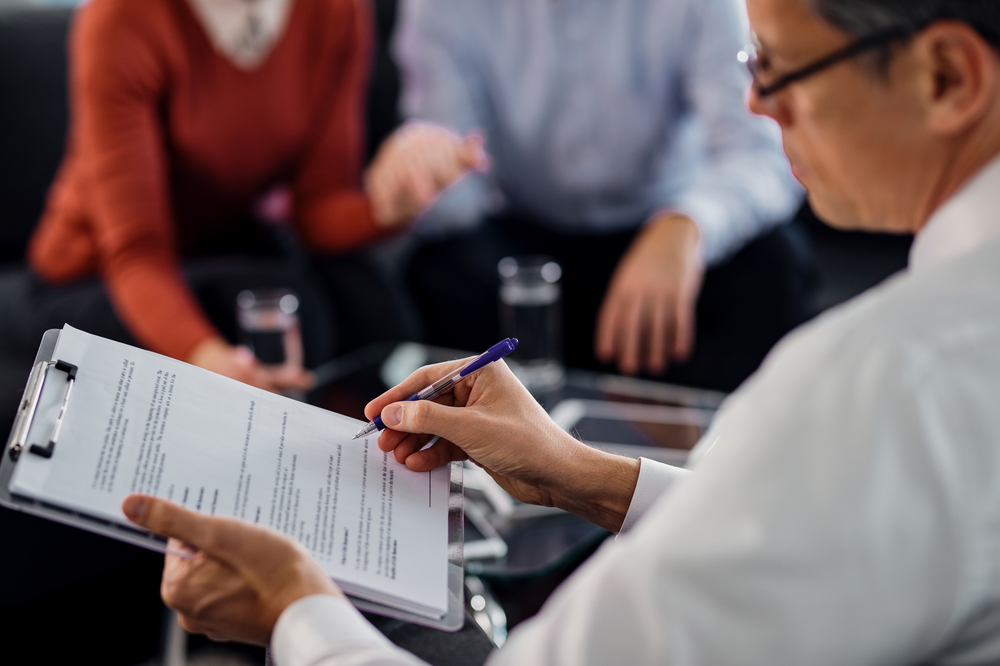

The `insurance.csv` dataset contains information about individuals and their medical charges. Each of the variables in the file is described below:

1. **age**: The individual's age (in years).
2. **sex**: The individual's sex (male for men and female for women).
3. **bmi**: The individual's Body Mass Index (BMI), a measure of weight relative to height.
4. **children**: Number of children or dependents the individual has.
5. **smoker**: Indicates whether the individual is a smoker (yes or no).
6. **region**: Geographic region where the individual resides (northeast, northwest, southeast, southwest).
7. **charges**: Total medical charges billed to the individual (in dollars).

These variables are commonly used to analyze and predict medical costs based on individuals' demographic and health characteristics.


### **Contents:**

#### Import the required packages

In [ ]:
# Install the required packages
%pip install scikit-learn # Machine learning package with classification, regression, clustering algorithms, etc.
%pip install pandas
%pip install matplotlib
%pip install seaborn
%pip install numpy

# Import the required packages
from sklearn.linear_model import LinearRegression # Linear regression with scikit-learn
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import numpy as np



#### Load the dataset



In [ ]:
# Locate the dataset relative to the notebook folder or repository root
from pathlib import Path

dataset_path = next(
    (folder / 'datasets' / 'insurance.csv'
     for folder in [Path.cwd(), *Path.cwd().parents]
     if (folder / 'datasets' / 'insurance.csv').is_file()),
    None
)
if dataset_path is None:
    raise FileNotFoundError('Run this notebook from within the ArtificialIntelligence repository.')
insurance = pd.read_csv(dataset_path)

# Display the first 10 rows of the loaded dataset
insurance.head(10)

In [ ]:
# Print the unique values of 'region' 
insurance['region'].unique()

#### Data preprocessing

In [ ]:
# Encode the categorical variables 'sex' and 'smoker' by replacing labels (label encoding)
insurance['sex'] = insurance['sex'].replace({'female': 0, 'male': 1})
insurance['smoker'] = insurance['smoker'].replace({'no': 0, 'yes': 1})

# Encode region, using northeast as the reference category
# Dropping one category avoids redundant columns when fitting an intercept
insurance = pd.get_dummies(insurance, columns=['region'], drop_first=True, dtype=int)

# Display the first 10 rows after preprocessing
insurance.head(10)

#### Prepare the variables `X` and `y`

In [ ]:
# Select the independent variables (X)
X = insurance.drop('charges', axis=1)
X

In [ ]:
# Select the dependent variable (y)
y = insurance['charges']
y

#### Split the data into training and test sets

In [ ]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

#### Instantiate a Linear Regression model and fit it with the values of `X_train` and `y_train`

In [ ]:
# Create an instance of the linear regression model
regression_model = LinearRegression()

# Fit the model to the training data
regression_model.fit(X_train, y_train)

##### **(Optional)** Save the model in .pkl format

The `.pkl` format is a file extension used to store serialized objects in Python through the `pickle` module. This module allows Python objects to be converted into a sequence of bytes, making it easier to store them in files or transmit them over networks. `.pkl` files are commonly used to save trained machine learning models, complex data structures, or any other object that needs to persist between program execution sessions. Deserializing these files allows objects to be restored to their original state, keeping their structure and data intact.

In [ ]:
# Save the model for future use
import joblib
joblib.dump(regression_model, 'regression_model.pkl')

##### **(Optional)** Load the model in .pkl format

In [ ]:
# Load the saved model
regression_model = joblib.load('regression_model.pkl')

#### Get the coefficients and intercept of the regression model

In the context of linear regression, the coefficients and intercept are fundamental parameters that define the relationship between the independent (predictor) variables and the dependent (response) variable.

##### *a) Coefficients*
The coefficients (also known as weights or betas) represent the magnitude and direction of the relationship between each independent variable and the dependent variable. In a multiple linear regression equation, each coefficient indicates how much the dependent variable changes when the corresponding independent variable increases by one unit, holding the other independent variables constant. Mathematically, if we have a linear regression equation of the form:

$y = \beta_0 + \beta_1 X_1 + \beta_2 X_2 + \ldots + \beta_n X_n$

where:
- $y$ is the dependent (target) variable.
- $\beta_0$ is the intercept.
- $\beta_1, \beta_2, \ldots, \beta_n $ are the coefficients of the independent variables $X_1, X_2, \ldots, X_n$.

##### *b) Intercept*
The intercept $\beta_0$ is the value of the dependent variable when all the independent variables are equal to zero. It represents the point where the regression line crosses the $y$ axis. In other words, it is the predicted value of $y$ when there is no influence from the independent variables.

##### Example:
If we have a multiple linear regression equation with two independent variables, it could look like this:

$y = 3 + 2X_1 - 4X_2$

In this case:
- The intercept $\beta_0$ is 3.
- The coefficient of $X_1$ ($\beta_1$) is 2, which means that for each one-unit increase in $X_1$, $y$ increases by 2 units.
- The coefficient of $X_2$ ($\beta_2$) is -4, which means that for each one-unit increase in $X_2$, $y$ decreases by 4 units.

These parameters are essential for interpreting the linear regression model and understanding how the independent variables affect the dependent variable.

In [ ]:
# Get the coefficients 
coefficients = regression_model.coef_
coefficients

In [ ]:
# Get the intercept 
intercept = regression_model.intercept_
intercept

In [ ]:
# Define the regression line equation
line_equation = 'y = ' + ' + '.join([f'{coefficients[i]}*X{i}' for i in range(len(coefficients))]) + f' + {intercept}'
print(f'Regression line equation: {line_equation}')

With the regression line equation, we can make predictions about medical charges based on the input features. This equation allows us to understand how each feature influences the final outcome, providing a clear mathematical relationship between the independent variables (features) and the dependent variable (medical charges). By applying this equation to new data, we can estimate the expected medical charges, which is useful for predictive analysis, informed decision-making, and resource planning in healthcare. In addition, the regression line equation makes it easier to interpret the coefficients, helping us identify which factors have the greatest impact on medical costs.

The coefficients represent the expected change in medical charges for a one-unit increase in the corresponding independent variable, holding the other variables constant.

Their interpretation depends on the variable's units and encoding:

1. **Numerical variables**: A coefficient describes the change in predicted charges per unit of the variable. Raw coefficient magnitudes cannot be compared directly across variables measured on different scales.
2. **Binary variables**: A coefficient describes the difference in predicted charges between the category coded as 1 and the category coded as 0, holding the other variables constant. For the region indicators, the reference category is `northeast`.

The sign indicates the direction of the fitted association:

- **Positive coefficient**: A higher value is associated with higher predicted medical charges.
- **Negative coefficient**: A higher value is associated with lower predicted medical charges.

Standardizing the predictors makes coefficient magnitudes more comparable in terms of a one-standard-deviation change. However, correlated predictors can make coefficients unstable, and coefficient magnitude alone does not establish predictive importance, statistical significance, or causality.

In [ ]:
# Create a DataFrame to make interpretation easier
coef_df = pd.DataFrame({'Variable': X.columns, 'Coefficient': coefficients})

# Sort by absolute coefficient magnitude; the predictors have different units
coef_df['Abs_Coefficient'] = coef_df['Coefficient'].abs()

# Sort the coefficients from highest to lowest
coef_df = coef_df.sort_values(by='Abs_Coefficient', ascending=False)

print(coef_df)

In [ ]:
# Plot the coefficients sorted from highest to lowest in a bar chart
sns.barplot(x='Coefficient', y='Variable', data=coef_df, palette='coolwarm')

plt.xlabel('Coefficient')
plt.ylabel('Variable')
plt.title('Linear regression coefficients')
plt.show()

#### Calculate the model evaluation metrics (making predictions on the test set)

In the context of linear regression, it is essential to evaluate the model's performance to understand its accuracy and generalization ability. There are several evaluation metrics that help us quantify the error and quality of the model's predictions. Among the most common are:

1. **Mean Squared Error (MSE)**: This metric calculates the average of the squared errors, that is, the difference between the predicted values $\hat{y}_i$ and the actual values $y_i$. MSE heavily penalizes large errors due to squaring, making it a metric that is sensitive to outliers. A lower MSE indicates a better fit of the model to the data. The MSE formula is:
   
   $\text{MSE} = \frac{1}{n} \sum_{i=1}^{n} (y_i - \hat{y}_i)^2$
   
   where $n$ is the number of observations.

2. **R-squared (R²)**: Also known as the coefficient of determination, this metric indicates the proportion of the variance in the dependent variable that is explained by the model's independent variables. For a nonconstant target, $R^2$ has a maximum of $1$ and can be negative. A value of $1$ indicates perfect predictions, while $0$ corresponds to predicting the mean of the target values in the evaluation set. A negative value means that the predictions are worse than that mean-based reference. This reference is distinct from the training-mean baseline evaluated below. The $R^2$ formula is:
   
   $R^2 = 1 - \frac{\sum_{i=1}^{n} (y_i - \hat{y}_i)^2}{\sum_{i=1}^{n} (y_i - \bar{y})^2}$
   
   where $\bar{y}$ is the mean of the actual values $y_i$.

3. **Mean Absolute Error (MAE)**: This metric calculates the average of the absolute errors, that is, the absolute difference between the predicted values $\hat{y}_i$ and the actual values $y_i$. Unlike MSE, MAE does not penalize large errors as much, making it more robust to outliers. A lower MAE indicates better model performance. The MAE formula is:
   
   $\text{MAE} = \frac{1}{n} \sum_{i=1}^{n} |y_i - \hat{y}_i|$
   
   where $n$ is the number of observations.

These metrics provide different perspectives on model performance and, when used together, can provide a more complete and robust evaluation of the quality of the linear regression model's predictions.

In [ ]:
# Make predictions on the test set
y_pred = regression_model.predict(X_test)

# Import the metrics to evaluate the model
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error

# Calculate the evaluation metrics
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mse)

# Print the evaluation metrics
print(f'Mean Squared Error (MSE): {mse}')
print(f'Coefficient of Determination (R^2): {r2}')
print(f'Mean Absolute Error (MAE): {mae}')
print(f'Root Mean Squared Error (RMSE): {rmse}')

#### Compare against a mean-prediction baseline

A baseline predicts the mean medical charge from the training set for every test case. Compare both models on the same test set: lower MAE and RMSE indicate smaller errors, measured in dollars. The training mean is used to avoid learning from the test targets.

In [ ]:
from sklearn.dummy import DummyRegressor

baseline_model = DummyRegressor(strategy='mean')
baseline_model.fit(X_train, y_train)
y_pred_baseline = baseline_model.predict(X_test)

comparison = pd.DataFrame({
    'Model': ['Training mean baseline', 'Linear regression'],
    'MAE ($)': [mean_absolute_error(y_test, y_pred_baseline), mae],
    'RMSE ($)': [np.sqrt(mean_squared_error(y_test, y_pred_baseline)), rmse],
    'R²': [r2_score(y_test, y_pred_baseline), r2]
})
print(comparison.to_string(index=False))

#### Inspect the residuals

A residual is the actual charge minus the predicted charge. Positive residuals indicate underestimation; negative residuals indicate overestimation. Look for residuals scattered around zero. Curves or distinct groups may suggest relationships the model misses, while a widening spread may indicate that error variability changes with predicted charges.

In [ ]:
residuals = y_test - y_pred

plt.figure(figsize=(8, 5))
plt.scatter(y_pred, residuals, color='blue', alpha=0.5, s=15)
plt.axhline(0, color='red', linestyle='--')
plt.xlabel('Predicted medical charges ($)')
plt.ylabel('Residuals: actual - predicted ($)')
plt.title('Test-set residuals vs. predicted medical charges')
plt.tight_layout()
plt.show()

#### Make predictions for a new insurance company customer

In [ ]:
# Define a new test case with the following values
new_case = pd.DataFrame({
    'age': [30],  # Age
    'sex': [1],  # Gender (0: female, 1: male)
    'bmi': [19],  # Body mass index
    'children': [1],  # Number of children
    'smoker': [0],  # Smoker (0: no, 1: yes)
    'region_northwest': [1],  # Northwest region
    'region_southeast': [0],  # Southeast region
    'region_southwest': [0]  # Southwest region
})

# Make the prediction with the new test case
prediction = regression_model.predict(new_case)

# Print the prediction result
print(f'The estimated cost of medical insurance is: ${prediction[0]:.2f}')

In the case of multiple regression, where you have more than one independent variable, the relationship between the independent variables and the dependent variable is represented in a **higher-dimensional space**. Therefore, instead of a regression line (which applies to simple regression with a single independent variable), you would have a hyperplane in a multidimensional space.

However, you can visualize the relationship between the actual values and the predicted values in a scatter plot, as shown below. This type of plot is useful for evaluating the accuracy of the model's predictions.

In [ ]:
# Plot the actual values vs the predicted values
plt.figure(figsize=(10, 6))
plt.scatter(y_test, y_pred, color='blue', alpha=0.7, s=10)
plt.title('Actual charges vs. Predicted charges')
plt.xlabel('Actual values')
plt.ylabel('Predicted values')
plt.plot([min(y_test), max(y_test)], [min(y_test), max(y_test)], color='red', linestyle='--')  # Reference line
plt.legend(['Predicted values', 'Reference line'])
plt.show()

In this plot:
- The blue points represent the actual values against the predicted values.
- The dashed red line is a reference line that indicates where the points would be if the predictions were perfect (that is, $y_{\text{actual}} = y_{\text{predicted}}$).

This plot allows you to visualize how close the predictions are to the actual values. If the predictions are perfect, all the points will fall on the reference line.

**Note:** Negative predicted values can occur because ordinary linear regression does not constrain its predictions. Negative medical charges have no practical meaning.

Possible approaches include:

1. **Target transformation**: Consider fitting the model to `log1p(charges)` and converting predictions back with `expm1`. Evaluate performance in dollars after the inverse transformation; this changes the fitting objective and may introduce retransformation bias. Standardizing the predictors alone does not prevent negative predictions.

2. **Models with an appropriate output range**: Consider a model designed for positive targets, such as a Gamma regressor with a log link when all charges are strictly positive. `LinearRegression(positive=True)` only constrains the coefficients to be nonnegative; it does not guarantee nonnegative predictions.

3. **Post-processing predictions**: If the application requires it, clip negative predictions to zero and evaluate the resulting predictions explicitly.

## Simple Linear Regression

As an example, a feature can be fitted with simple linear regression. This will allow you to visualize the relationship between a single independent variable and the dependent variable.

We will fit a simple linear regression using one feature, for example, `bmi`.

In [ ]:
# Copy the 'insurance.csv' dataset into a new DataFrame
df = insurance.copy()

X_2 = df[['bmi']]
y_2 = df['charges']

# Split the data into training and test sets
X_train2, X_test2, y_train2, y_test2 = train_test_split(X_2, y_2, test_size=0.2, random_state=42)

# Create and train the linear regression model
model = LinearRegression()
model.fit(X_train2, y_train2)

# Make predictions
y_pred = model.predict(X_test2)

# Plot the data and the regression line
plt.figure(figsize=(5, 3))
plt.scatter(X_test2, y_test2, color='blue', alpha=0.7, s=10, label='Actual data')
plt.plot(X_test2, y_pred, color='red', linewidth=0.5, label='Regression line')
plt.title('Simple linear regression: BMI vs. Medical charges')
plt.xlabel('BMI')
plt.ylabel('Medical charges')
plt.legend()
plt.show()

In [ ]:
# Extract the linear regression coefficients
coefficients = model.coef_
intercept = model.intercept_

# Print the regression line equation
print(f'Regression line equation: y = {coefficients[0]:.2f}X + {intercept:.2f}')

In this example:

1. **Data**: We use the `bmi` feature and the `charges` target variable.
2. **Data splitting**: We split the data into training and test sets.
3. **Model**: We create and train a simple linear regression model.
4. **Predictions**: We make predictions on the test set.
5. **Plot**: We plot the actual data and the fitted regression line.

This plot will allow you to visualize how BMI relates to medical charges and how the fitted regression line represents this relationship.

## Dataset standardization

In [ ]:
# Standardize the data in the 'insurance.csv' dataset with the StandardScaler function from scikit-learn
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

# Apply standardization to the training and test sets
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [ ]:
# Convert the standardized data to DataFrames to make interpretation easier
X_train_scaled_df = pd.DataFrame(X_train_scaled, columns=X.columns)
X_test_scaled_df = pd.DataFrame(X_test_scaled, columns=X.columns)

# Display the first rows of the standardized data
X_train_scaled_df.head()

In [ ]:
# Create an instance of the linear regression model
scaled_regression_model = LinearRegression()

# Fit the linear regression model with the standardized data
scaled_regression_model.fit(X_train_scaled_df, y_train)

In [ ]:
# Make predictions on the test set
y_pred_scaled = scaled_regression_model.predict(X_test_scaled_df)

# Calculate the evaluation metrics
mse_scaled = mean_squared_error(y_test, y_pred_scaled)
r2_scaled = r2_score(y_test, y_pred_scaled)
mae_scaled = mean_absolute_error(y_test, y_pred_scaled)
rmse_scaled = np.sqrt(mse_scaled)

# Print the evaluation metrics
print(f'Mean Squared Error (MSE) - Scaled Data: {mse_scaled}')
print(f'Coefficient of Determination (R^2) - Scaled Data: {r2_scaled}')
print(f'Mean Absolute Error (MAE) - Scaled Data: {mae_scaled}')
print(f'Root Mean Squared Error (RMSE) - Scaled Data: {rmse_scaled}')

For ordinary least squares with an intercept, standardizing the predictors preserves the fitted predictions up to numerical precision. StandardScaler changes the scale of `X`, and the model adjusts its coefficients and intercept to compensate.

Scaling allows coefficients to be compared for a one-standard-deviation increase in each predictor. However, these magnitudes do not by themselves establish predictive importance or causality, and correlated predictors can affect their interpretation. For binary indicators, the scaled coefficient no longer represents a direct change from 0 to 1; use the unscaled coefficient for that interpretation.

In [ ]:
# Plot coefficient magnitudes for the linear regression model with standardized predictors
scaled_coefficients = scaled_regression_model.coef_
scaled_coef_df = pd.DataFrame({'Variable': X.columns, 'Coefficient': scaled_coefficients})
scaled_coef_df['Abs_Coefficient'] = scaled_coef_df['Coefficient'].abs() 
scaled_coef_df = scaled_coef_df.sort_values(by='Abs_Coefficient', ascending=False)
print(scaled_coef_df)

# Plot the coefficients sorted from highest to lowest in a bar chart
sns.barplot(x='Coefficient', y='Variable', data=scaled_coef_df, palette='coolwarm')
plt.xlabel('Coefficient')
plt.ylabel('Variable')
plt.title('Linear regression coefficients with standardized data')
plt.show()

In [ ]:
# Plot the linear regression coefficients with unstandardized data (coef_df) and compare them with the linear regression coefficients with standardized data (scaled_coef_df) to compare coefficient magnitudes before and after standardization
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
sns.barplot(x='Coefficient', y='Variable', data=coef_df, palette='coolwarm')
plt.xlabel('Coefficient')
plt.ylabel('Variable')
plt.title('Linear regression coefficients without standardization')
plt.subplot(1, 2, 2)
sns.barplot(x='Coefficient', y='Variable', data=scaled_coef_df, palette='coolwarm')
plt.xlabel('Coefficient')
plt.ylabel('Variable')
plt.title('Linear regression coefficients with standardized data')
plt.tight_layout()
plt.show()


___

### Activity

1. **Find a new dataset:**
   - **Find** a new dataset and **identify** the predictor and target variable(s).

In [ ]:
# Write your code here..



2. **Model Fitting:**
   - **Fit** a linear regression model.
   - **Evaluate** the model's performance (e.g., `RMSE`) based on its unit of measurement.
   - **Analyze** the most significant coefficients for the model.
   - (Optional) Use [`cross_val_score`](https://scikit-learn.org/stable/modules/cross_validation.html) with 5 folds. Calculate the mean RMSE and the standard deviation of all the scores obtained with cross-validation (optional).

In [ ]:
# Write your code here..


   
3. **Predicting New Records:**
   - Use the fitted model to **predict** the value of `y` for a new record with the `.predict` method.

In [ ]:
# Write your code here..


4. **Predicting New Records:**
   - Use the fitted model to **predict** the value of `y` for the previous record in an Excel spreadsheet.

Paste the screenshot here..

5. **Possible improvements:**
   - Suggest an improvement proposal to optimize **model performance**.

In [ ]:
# Write your code here..



### **Conclusions:**
Through this analysis, we have learned to use linear regression to predict the medical charges of an insurance company's customers. This technique allows us to better understand the relationships between different variables and make informed predictions that can guide medical insurance business strategies.

# **Grading Rubric**

1. Dataset source and description of variables: **1pts**
2. Fitting the linear regressor (simple or multiple): **1pts**
3. Calculating the *RMSE* metric and identifying its unit of measurement: **1pts** 
4. Predicting a **new example** using the `.predict` method in a Jupyter Notebook or `.py` script: **1pts**
5. Predicting the **new example** from the previous step using an Excel spreadsheet and comparing results: **3pts**
6. Proposing improvements to optimize the metrics: **3pts**